In [1]:
# Weekly Task Sheet: Data Visualization with Matplotlib and Seaborn
#GDG on Campus, AI/ML Team, COMSATS University, Attock Campus | Month 2
#Name: Aatiqa bibi

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic = sns.load_dataset("titanic")

In [2]:
#===========================================================================
#===============Part 1: Matplotlib==========================================
#===========================================================================

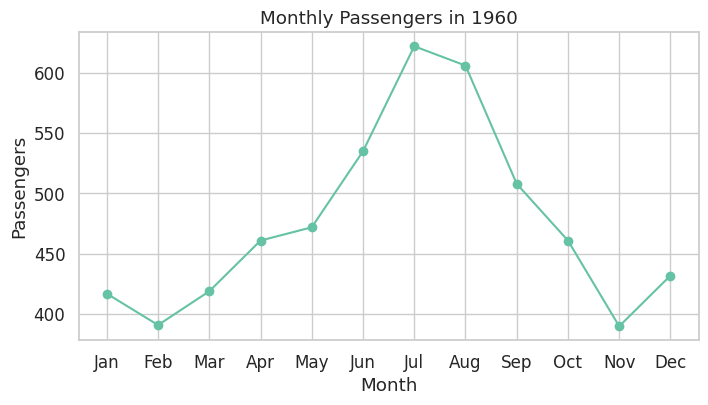

In [18]:
f = flights[flights["year"] == 1960]
plt.figure(figsize=(8,4))
plt.plot(f["month"], f["passengers"], marker="o")
plt.title("Monthly Passengers in 1960")
plt.xlabel("Month"); plt.ylabel("Passengers")
plt.grid(True)
plt.show()

### What does this chart tell us?
#Observation: Passengers are lowest in February and November (about 390), climb steadily from spring, and peak in July at 622 before falling again.
#Insight: Air travel is strongly seasonal. The summer holiday period drives demand, while late autumn and February are the quietest months.

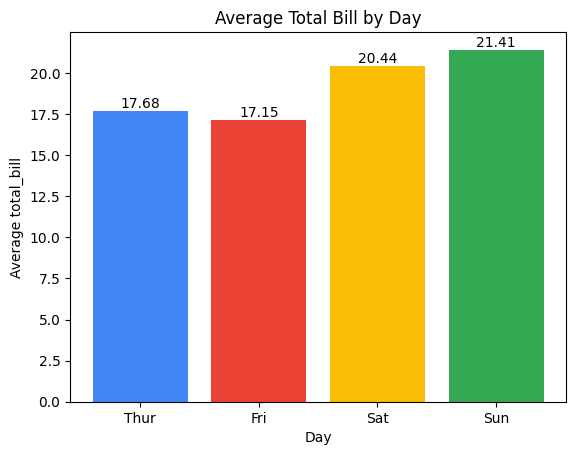

In [4]:
avg = tips.groupby("day", observed=True)["total_bill"].mean()
bars = plt.bar(avg.index.astype(str), avg.values, color=["#4285F4","#EA4335","#FBBC05","#34A853"])
plt.bar_label(bars, fmt="%.2f")
plt.title("Average Total Bill by Day")
plt.xlabel("Day"); plt.ylabel("Average total_bill")
plt.show()

### What does this chart tell us?
#Observation: Sunday has the highest average bill (about $21.41), followed by Saturday ($20.44). Thursday and Friday are lower, around $17 to $18.
#Insight: Weekend customers spend more per bill, likely because they dine in larger groups or order more on leisure days.

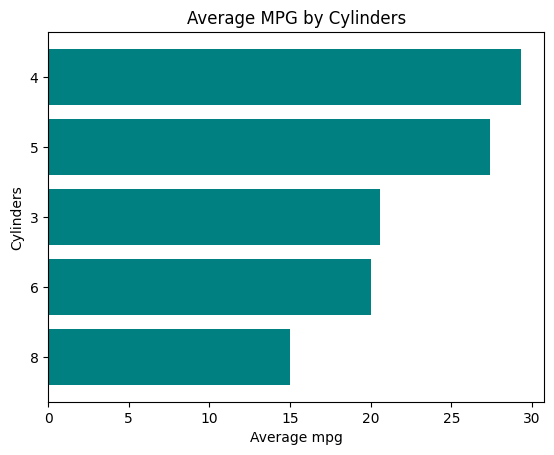

In [5]:
avg = mpg.groupby("cylinders")["mpg"].mean().sort_values()  # ascending so the highest shows on top
plt.barh(avg.index.astype(str), avg.values, color="teal")
plt.title("Average MPG by Cylinders")
plt.xlabel("Average mpg"); plt.ylabel("Cylinders")
plt.show()

### What does this chart tell us?
#Observation: 4-cylinder cars have the best average mpg (about 29.3), and 8-cylinder cars the worst (about 15). The 3-cylinder group (about 20.6) is an exception.
#Insight: Larger engines burn more fuel, so mpg generally falls as cylinders increase. The 3-cylinder group has very few cars, so its average is less reliable.

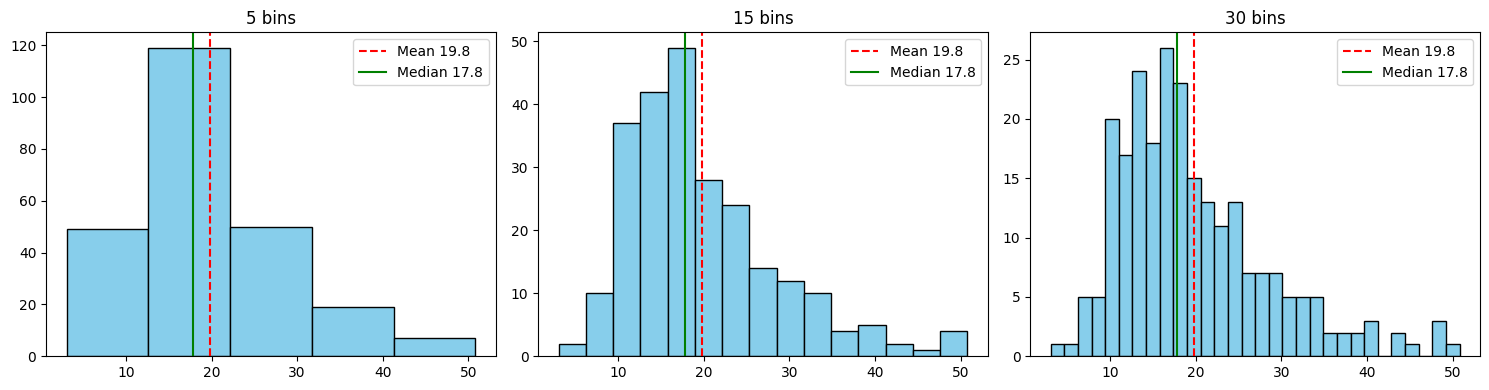

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
mean, median = tips["total_bill"].mean(), tips["total_bill"].median()
for ax, bins in zip(axes, [5, 15, 30]):
    ax.hist(tips["total_bill"], bins=bins, color="skyblue", edgecolor="black")
    ax.axvline(mean, color="red", linestyle="--", label=f"Mean {mean:.1f}")
    ax.axvline(median, color="green", linestyle="-", label=f"Median {median:.1f}")
    ax.set_title(f"{bins} bins"); ax.legend()
plt.tight_layout(); plt.show()


### What does this chart tell us?
#Observation: The distribution is right-skewed: most bills are between $10 and $25, with a long tail of a few large bills. The mean (19.79) is higher than the median (17.80).
#Insight: A few expensive bills pull the mean upward. Few bins (5) hide detail, while many bins (30) show more peaks but look noisier. About 15 bins is a good balance.

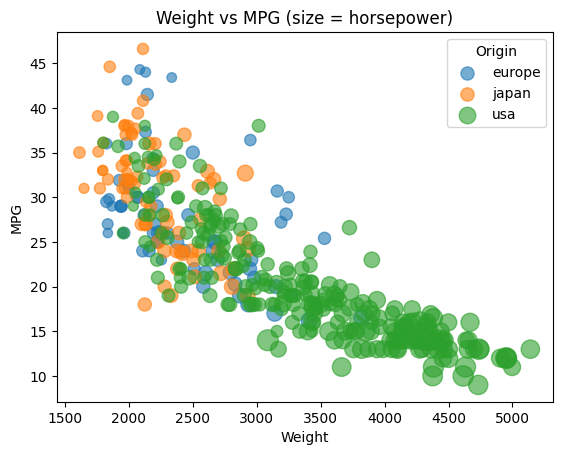

In [7]:
m = mpg.dropna(subset=["horsepower"])
for origin, g in m.groupby("origin"):
    plt.scatter(g["weight"], g["mpg"], s=g["horsepower"], alpha=0.6, label=origin)
plt.title("Weight vs MPG (size = horsepower)")
plt.xlabel("Weight"); plt.ylabel("MPG")
plt.legend(title="Origin")
plt.show()


### What does this chart tell us?
#Observation:As weight increases, mpg drops clearly (correlation about -0.83). USA cars are the heaviest (about 3,360) with the lowest mpg (about 20), while Japanese cars are lighter (about 2,220) with the highest mpg (about 30.5). Large points (high horsepower) sit in the heavy, low-mpg area.
#Insight:Heavy, powerful engines use more fuel. Origin matters because US manufacturers built larger cars in this period.

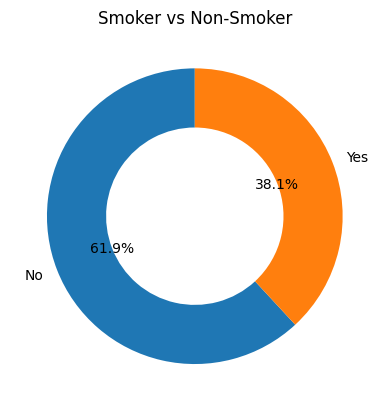

In [8]:
counts = tips["smoker"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
        wedgeprops={"width": 0.4})
plt.title("Smoker vs Non-Smoker")
plt.show()


### What does this chart tell us?
#Observation: Non-smokers make up about 61.9% of customers and smokers about 38.1% (151 vs 93 customers).
#Insight: Non-smokers outnumber smokers by roughly 3 to 2, so the dataset leans toward non-smoking parties.

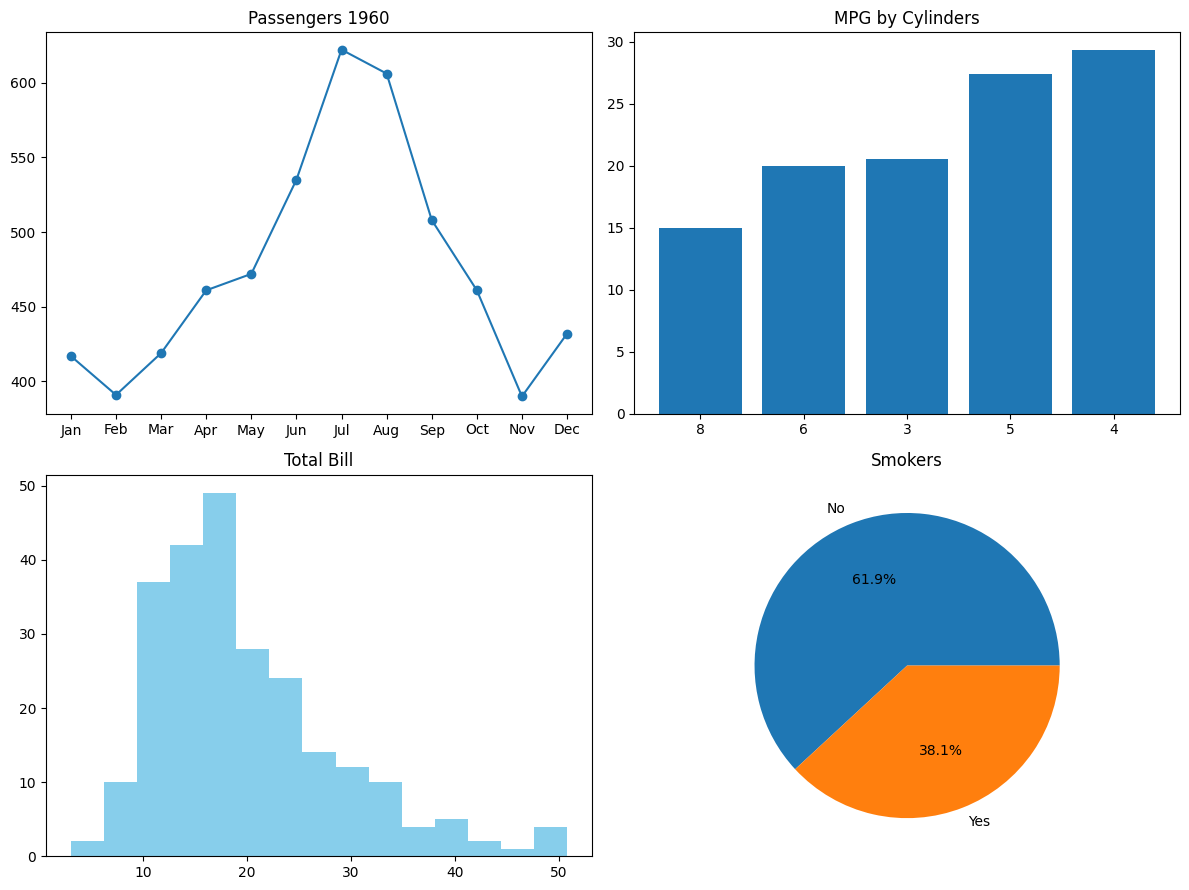

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12,9))
axes[0,0].plot(f["month"], f["passengers"], marker="o"); axes[0,0].set_title("Passengers 1960")
axes[0,1].bar(avg.index.astype(str), avg.values); axes[0,1].set_title("MPG by Cylinders")
axes[1,0].hist(tips["total_bill"], bins=15, color="skyblue"); axes[1,0].set_title("Total Bill")
axes[1,1].pie(counts, labels=counts.index, autopct="%1.1f%%"); axes[1,1].set_title("Smokers")
plt.tight_layout()
plt.savefig("dashboard.png", dpi=300)
plt.show()

### What does this chart tell us?
#Observation:** The dashboard shows seasonal flight demand (peak in July), higher weekend bills, a right-skewed bill distribution, and a majority of non-smoking customers.
#Insight:** Combining several small plots in one figure lets us compare different aspects of the data at a glance. Both datasets show patterns tied to time (season, day of week).

In [ ]:
#===========================================================================
#===============Part 1: Seaborn=============================================
#===========================================================================

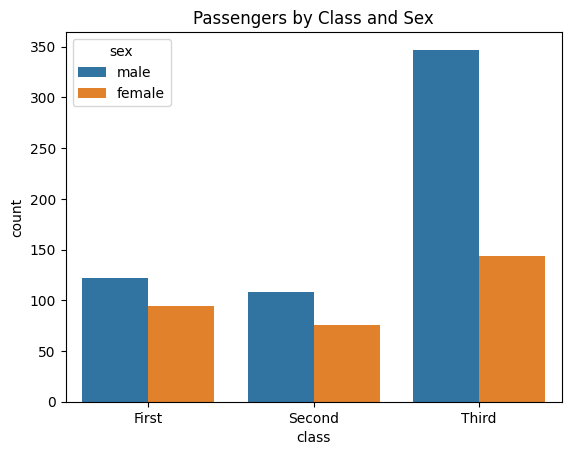

In [10]:
sns.countplot(data=titanic, x="class", hue="sex")
plt.title("Passengers by Class and Sex"); plt.show()


### What does this chart tell us?
#Observation:Third class has by far the most passengers (491), compared with 216 in First and 184 in Second. Men outnumber women in every class, most strongly in Third (347 men vs 144 women).
#Insight:Most passengers were in the cheapest class, and many were men travelling for work or migration. This helps explain the survival differences studied later.

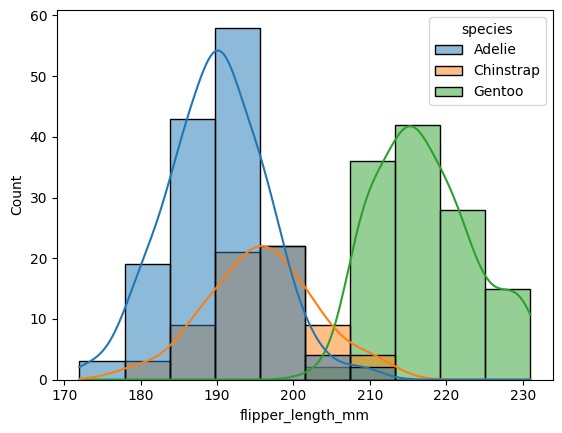

In [11]:
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", kde=True)
plt.show()


### What does this chart tell us?
#Observation: Gentoo penguins have the longest flippers (average about 217 mm). Adelie (about 190 mm) and Chinstrap (about 196 mm) overlap a lot.
#Insight:Flipper length separates Gentoo from the other two species well, but it is not enough alone to tell Adelie from Chinstrap.

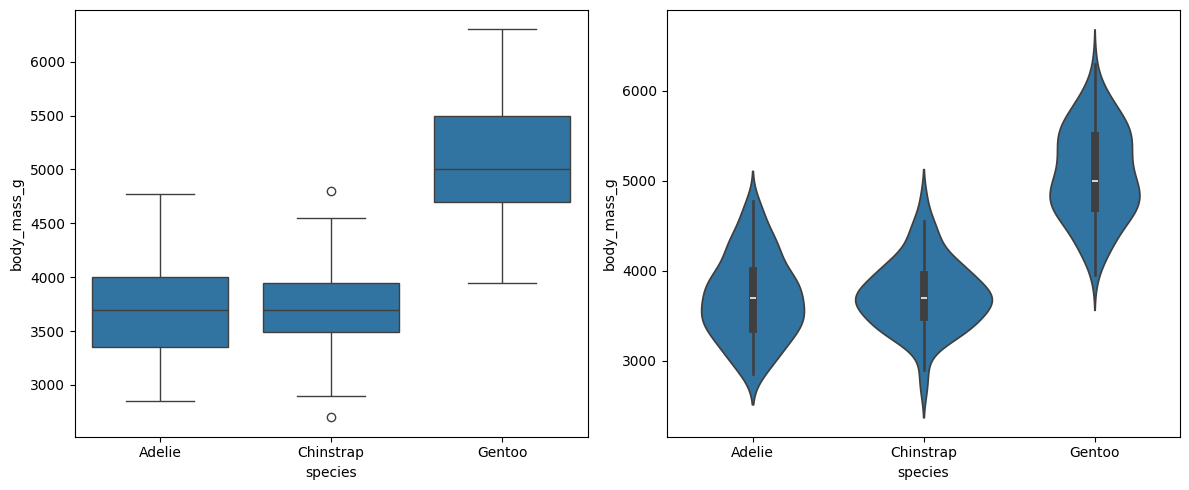

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(data=penguins, x="species", y="body_mass_g", ax=axes[0])
sns.violinplot(data=penguins, x="species", y="body_mass_g", ax=axes[1])
plt.tight_layout(); plt.show()

### What does this chart tell us?
#Observation: Gentoo penguins are clearly the heaviest (average about 5,076 g), while Adelie (about 3,701 g) and Chinstrap (about 3,733 g) are similar.
#Insight: The box plot shows the median, quartiles, and outliers clearly. The violin plot shows the same summary plus the full shape of the distribution, so you can see where most values are concentrated and whether there is more than one peak.

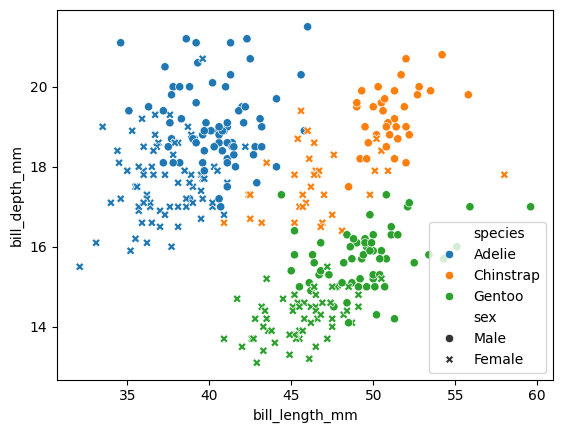

In [13]:
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm", hue="species", style="sex")
plt.show()

### What does this chart tell us?
#Observation:The species form three fairly distinct clusters. Gentoo have long but shallow bills (about 47.5 mm by 15 mm), Adelie have short deep bills, and Chinstrap have long deep bills. Males sit higher or further right than females within each species.
#Insight:Combining two bill measurements separates the species far better than one measurement alone. Sex causes a consistent size difference but does not change the cluster pattern.

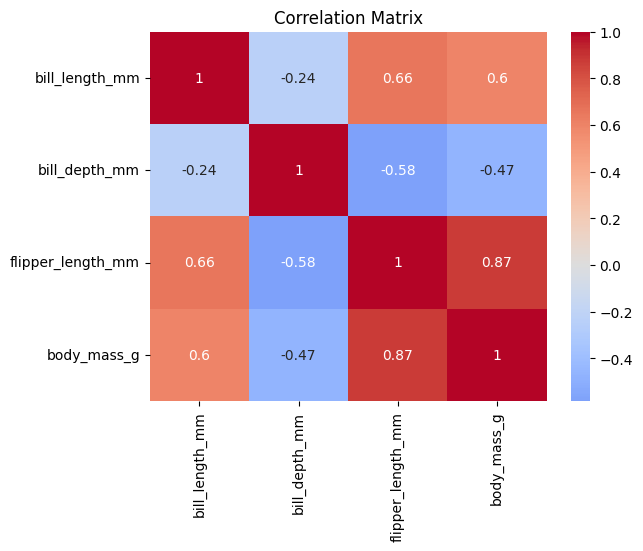

In [14]:
corr = penguins.select_dtypes("number").corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Matrix"); plt.show()

### What does this chart tell us?
#Observation:The strongest correlation is between flipper length and body mass (about 0.87). Bill depth is negatively correlated with flipper length and body mass, and bill length and bill depth have the weakest relationship (about -0.24).
#Insight:Bigger penguins have longer flippers and heavier bodies. The negative bill depth values appear because Gentoo (large body) have shallow bills, which mixes species together.

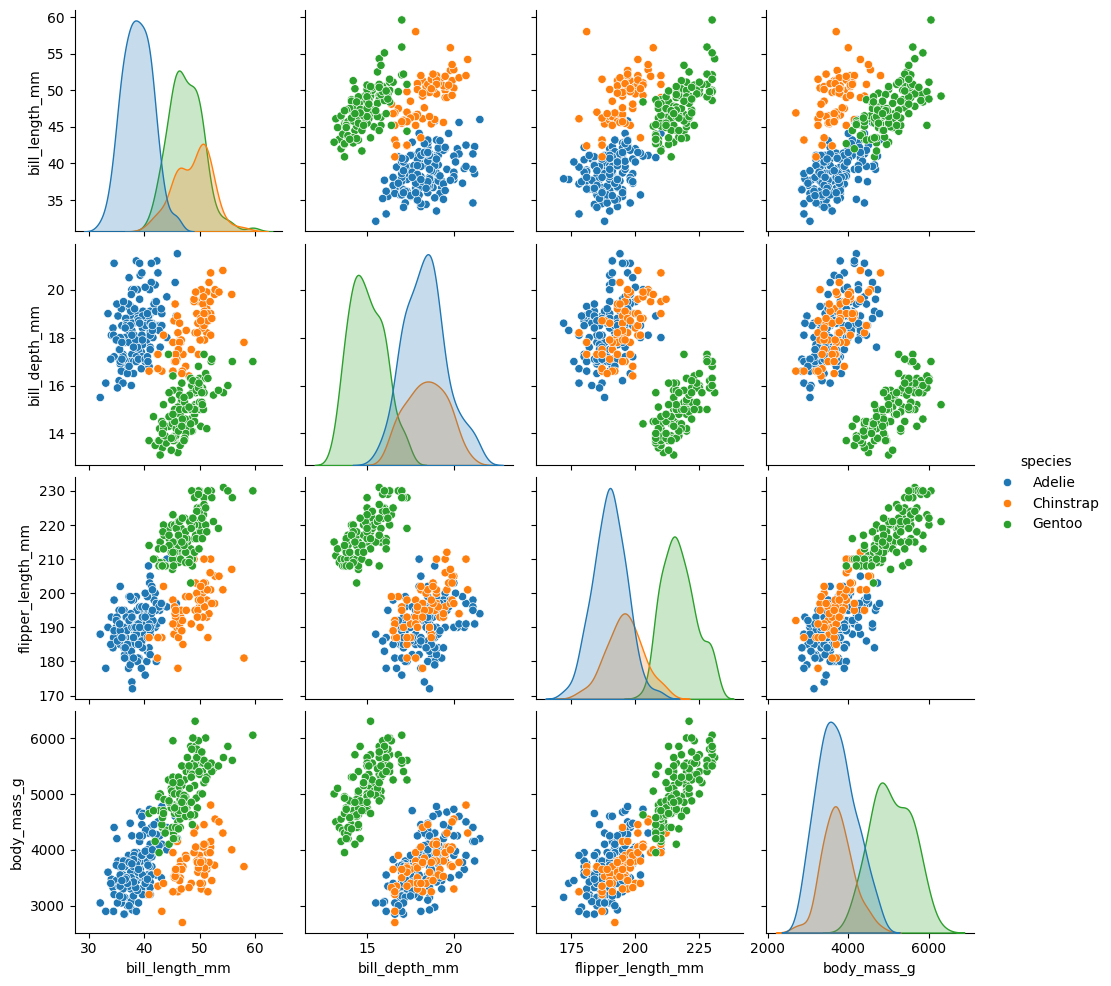

In [15]:
sns.pairplot(penguins, hue="species")
plt.show()

### What does this chart tell us?
#1. Gentoo is clearly separated.
#2. Flipper length and body mass are strongly and positively related.
#3. Adelie and Chinstrap overlap.

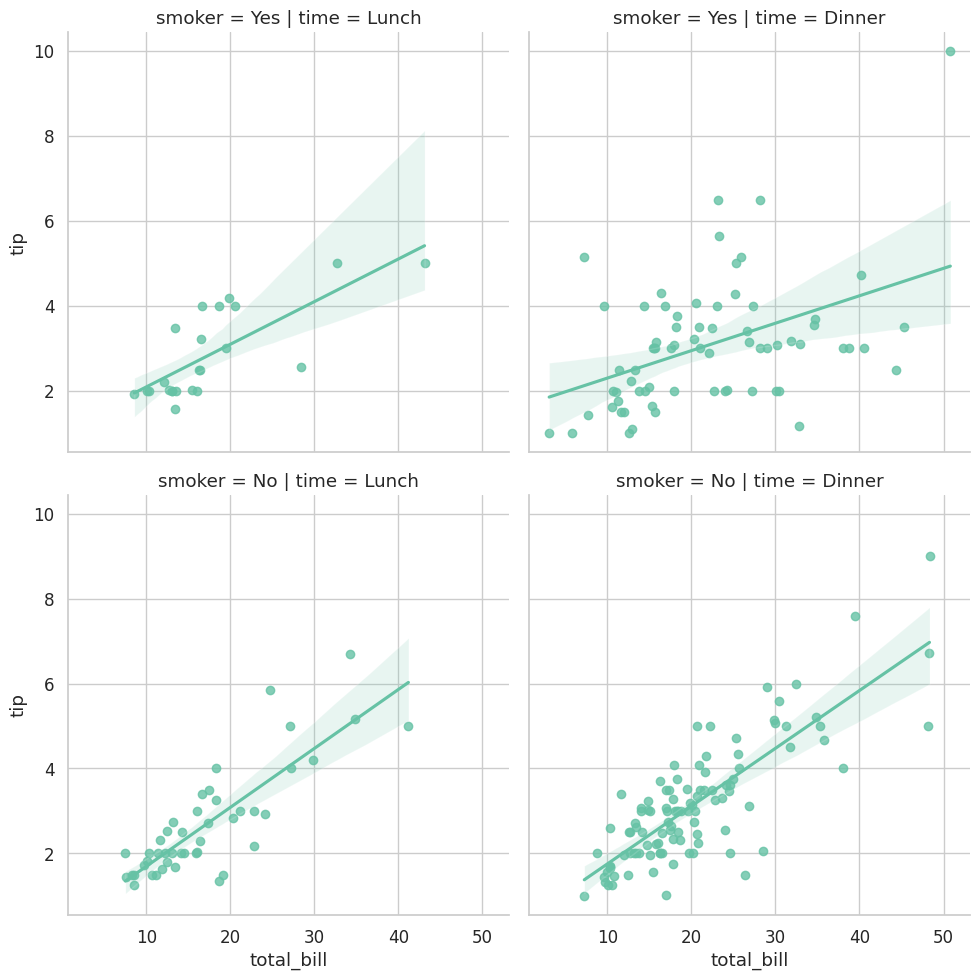

In [16]:
sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.1)
sns.lmplot(data=tips, x="total_bill", y="tip", col="time", row="smoker")
plt.show()


### What does this chart tell us?
#Observation: The regression line slopes upward in every panel: higher bills mean higher tips.
#Insight: Tips scale with the bill, which is consistent with tipping a percentage.